In [59]:
import numpy as np

data = np.genfromtxt('data/advertising.csv', delimiter=',').tolist()
print(data[:5])

[[nan, nan, nan, nan], [230.1, 37.8, 69.2, 22.1], [44.5, 39.3, 45.1, 10.4], [17.2, 45.9, 69.3, 12.0], [151.5, 41.3, 58.5, 16.5]]


In [60]:
data = np.genfromtxt('data/advertising.csv', delimiter=',', skip_header=1).tolist()
print(data[:5])

[[230.1, 37.8, 69.2, 22.1], [44.5, 39.3, 45.1, 10.4], [17.2, 45.9, 69.3, 12.0], [151.5, 41.3, 58.5, 16.5], [180.8, 10.8, 58.4, 17.9]]


In [61]:
# dataset
import matplotlib.pyplot as plt
import random
def get_column(data, index):
    result = [row[index] for row in data]
    return result

N = len(data)

# get tv
tv_data = get_column(data, 0)
print(tv_data[:5])

# get radio
radio_data = get_column(data, 1)
print(radio_data[:5])

# get newspaper
newspaper_data = get_column(data, 2)
print(newspaper_data[:5])

# get sales
sales_data = get_column(data, 2)
print(sales_data[:5])
print(f'N = {N}')

[230.1, 44.5, 17.2, 151.5, 180.8]
[37.8, 39.3, 45.9, 41.3, 10.8]
[69.2, 45.1, 69.3, 58.5, 58.4]
[69.2, 45.1, 69.3, 58.5, 58.4]
N = 200


In [62]:
# compute output and loss
def predict(x1, x2, x3, w1, w2, w3, b):
    return w1 * x1 + w2 * x2 + w3 * x3 + b

def compute_loss(y_hat, y):
    return (y_hat - y) ** 2
def compute_gradient_wi(xi, y, y_hat):
    dl_dwi = 2 * xi * (y_hat - y)
    return dl_dwi

# update weights
def update_weight_wi(wi, dl_dwi, lr):
    wi = wi - lr * dl_dwi
    return wi
def update_weight_b(b, dl_db, lr):
    b = b - lr * dl_db
    return b

In [63]:
def initialize_params():
    w1 = random.gauss(mu = 0.0, sigma=0.01)
    w2 = random.gauss(mu = 0.0, sigma=0.01)
    w3 = random.gauss(mu = 0.0, sigma=0.01)
    b = 0
    return w1, w2, w3, b
w1, w2, w3, b = initialize_params()
print(w1, w2, w3, b)

0.0008586766179500018 0.010571670256293152 0.010905108063878033 0


In [64]:
epoch_max = 50
lr = 1e-5
losses = []

for epoch in range(epoch_max):
    for i in range(N):
        # get a sample
        x1 = tv_data[i]
        x2 = radio_data[i]
        x3 = newspaper_data[i]
        y = sales_data[i]

        # compute output
        y_hat = predict(x1, x2, x3, w1, w2, w3, b)

        # compute loss
        loss = compute_loss(y_hat, y)

        # compute graident w1, w2, w3, b
        dl_dw1 = compute_gradient_wi(x1, y, y_hat)
        dl_dw2 = compute_gradient_wi(x2, y, y_hat)
        dl_dw3 = compute_gradient_wi(x3, y, y_hat)

        # update parameters
        w1 = update_weight_wi(w1, dl_dw1, lr)
        w2 = update_weight_wi(w2, dl_dw2, lr)
        w3 = update_weight_wi(w3, dl_dw3, lr)

        # logging
        losses.append(loss)

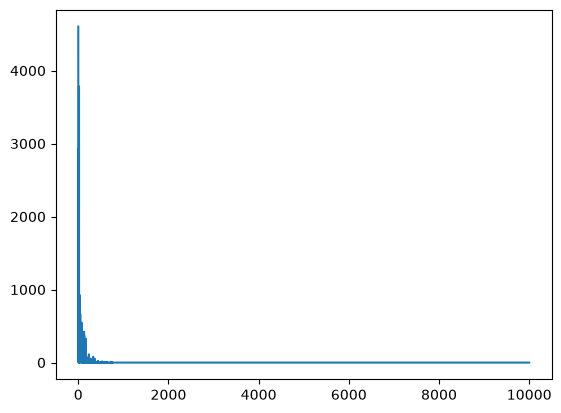

In [65]:
plt.plot(losses)
plt.show()

In [66]:
print(w1, w2, w3, b)

-2.7664269361833946e-18 1.3903954349988112e-16 0.9999999999999998 0


In [67]:
def predict(x1, x2, x3, w1, w2, w3, b):
    return w1*x1 + w2*x2 + w3*x3 + b

# given new data
tv = 19.2
radio = 35.9 
newspaper = 51.3

sales = predict(tv, radio, newspaper, w1, w2, w3, b)
print(f'predicted sales is {sales}')

predicted sales is 51.29999999999999


In [68]:
# [230.1, 37.8, 69.2, 22.1]

tv = 230.1
radio = 37.8 
newspaper = 69.2

sales = predict(tv, radio, newspaper, w1, w2, w3, b)
print(f'predicted sales is {sales}')

predicted sales is 69.19999999999999
